# 02 · Modelos de difusión con la librería 🤗 diffusers: preentrenamiento y fine-tuning con LoRA
**Generación · Especialización en Inteligencia Artificial** — Jahir Ávila

Stable Diffusion no puede entrenarse ni ajustarse en este entorno (≈ 860 M parámetros en la U-Net, GPU obligatoria). Para
reproducir **el mismo procedimiento con la misma librería** a una escala que corre en CPU:

1. Se construye con `diffusers` una **U-Net** (`UNet2DModel`) y un **programador de ruido DDPM** (`DDPMScheduler`): los mismos
   bloques que usa Stable Diffusion.
2. **Preentrenamiento:** se entrena la U-Net a predecir el ruido en Fashion-MNIST (32 × 32), **excluyendo la clase "bolso"**.
3. **Fine-tuning con LoRA** (como se hace con Stable Diffusion): se congelan los pesos y se entrenan adaptadores de bajo rango
   con **solo 100 imágenes de bolsos**, para enseñarle un concepto nuevo. Se compara con un fine-tuning completo.
4. Se mide cuánto del concepto nuevo aprendió el modelo con un clasificador independiente.

El notebook 03 contiene el código equivalente para Stable Diffusion 1.5 en Google Colab con GPU.

In [1]:
# Configuración del entorno (Google Colab o local)
# >>> Pegue aquí la URL de su repositorio de GitHub (solo se usa al ejecutar en Google Colab) <<<
REPO_URL = "https://github.com/USUARIO/REPOSITORIO.git"

import os, sys
if "google.colab" in sys.modules:
    carpeta_repo = REPO_URL.rstrip("/").split("/")[-1].removesuffix(".git")
    if not os.path.exists("src") and not os.path.exists(carpeta_repo):
        !git clone -q {REPO_URL}
    if os.path.exists(carpeta_repo):
        os.chdir(carpeta_repo)
    !pip -q install diffusers peft
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.path.abspath("src"))
for d in ["resultados", "figuras", "modelos"]: os.makedirs(d, exist_ok=True)
print("Directorio de trabajo:", os.getcwd())

Directorio de trabajo: /home/claude/generacion-gan-difusion


In [2]:
import json, time, inspect, numpy as np, pandas as pd, torch, torch.nn as nn, matplotlib.pyplot as plt
AZUL, NARANJA, AQUA, AMARILLO, VIOLETA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#4a3aa7", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0", "font.size": 10,
                     "axes.titleweight": "bold", "legend.frameon": False, "lines.linewidth": 1.6})
def guardar(fig, nombre): fig.savefig(f"figuras/{nombre}.png")
def mosaico(imgs, filas, ax=None, titulo=None):
    """imgs: (N, 1, H, W) en [-1, 1] -> cuadrícula."""
    imgs = np.asarray(imgs)[:, 0]; n, h, w = imgs.shape; cols = int(np.ceil(n / filas))
    lienzo = np.ones((filas * (h + 2), cols * (w + 2)))
    for k in range(n):
        r, c = divmod(k, cols); lienzo[r * (h + 2):r * (h + 2) + h, c * (w + 2):c * (w + 2) + w] = (np.clip(imgs[k], -1, 1) + 1) / 2
    ax = ax or plt.gca(); ax.imshow(lienzo, cmap="gray", vmin=0, vmax=1); ax.axis("off")
    if titulo: ax.set_title(titulo)
    return ax
dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(42); np.random.seed(42)
print("PyTorch", torch.__version__, "| dispositivo:", dispositivo)
import copy
from diffusers import UNet2DModel, DDPMScheduler, DDIMScheduler
import diffusers, peft
from peft import LoraConfig, inject_adapter_in_model
from datos import cargar_fashion, CLASES_FASHION
print("diffusers", diffusers.__version__, "| peft", peft.__version__)

PyTorch 2.15.0+cu132 | dispositivo: cpu


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


diffusers 0.43.0 | peft 0.22.0


## 1. Datos

Preentrenamiento: 54000 imágenes de 9 clases | Fine-tuning: 100 imágenes de 'bolso'


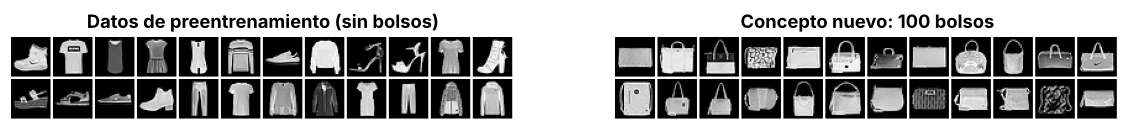

In [3]:
X, Y = cargar_fashion("train"); Xt, Yt = cargar_fashion("test")
BOLSO = CLASES_FASHION.index("bolso")
X_base = torch.tensor(X[Y != BOLSO])                        # preentrenamiento: 9 clases, SIN bolsos
idx_bolso = np.where(Y == BOLSO)[0]
X_bolso = torch.tensor(X[np.random.default_rng(0).choice(idx_bolso, 100, replace=False)])   # 100 imágenes para el ajuste
print(f"Preentrenamiento: {len(X_base)} imágenes de 9 clases | Fine-tuning: {len(X_bolso)} imágenes de '{CLASES_FASHION[BOLSO]}'")
fig, axes = plt.subplots(1, 2, figsize=(13, 2.8))
mosaico(X_base[:24], 2, axes[0], "Datos de preentrenamiento (sin bolsos)"); mosaico(X_bolso[:24], 2, axes[1], "Concepto nuevo: 100 bolsos")
guardar(fig, "02_datos"); plt.show()

## 2. Proceso de difusión hacia adelante (forward)

Se agrega ruido gaussiano en $T=1000$ pasos: $x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\varepsilon$, con
$\varepsilon\sim\mathcal N(0,I)$. En $t=T$ la imagen es ruido puro. La red aprende el proceso inverso: dado $x_t$ y $t$, predecir
$\varepsilon$ (pérdida $\lVert\varepsilon-\varepsilon_\theta(x_t,t)\rVert^2$, Ho et al., 2020).

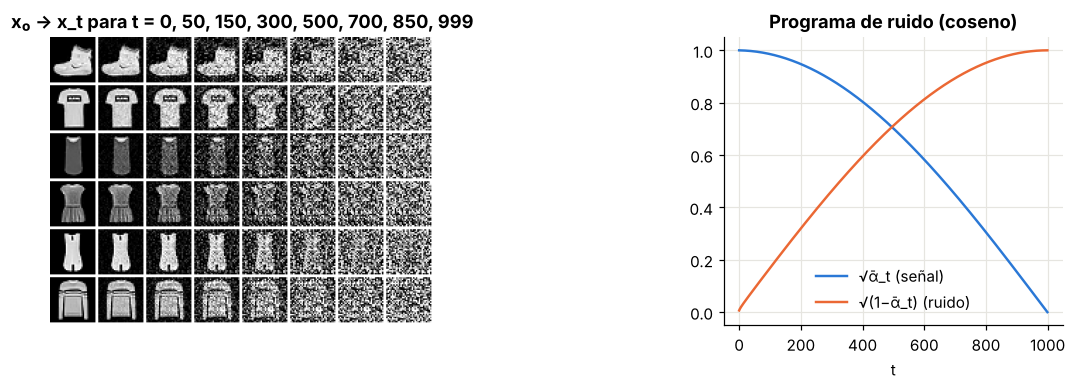

In [4]:
ruido_sch = DDPMScheduler(num_train_timesteps=1000, beta_schedule="squaredcos_cap_v2")
x0 = X_base[:6]; eps = torch.randn_like(x0)
pasos = [0, 50, 150, 300, 500, 700, 850, 999]
fig, axes = plt.subplots(1, 2, figsize=(14, 3.4), gridspec_kw={"width_ratios": [2.2, 1]})
fila = torch.cat([ruido_sch.add_noise(x0, eps, torch.full((6,), t)) for t in pasos])
fila = fila.view(len(pasos), 6, 1, 32, 32).transpose(0, 1).reshape(-1, 1, 32, 32)
mosaico(fila, 6, axes[0], "x₀ → x_t para t = " + ", ".join(map(str, pasos)))
ab = ruido_sch.alphas_cumprod.numpy()
axes[1].plot(np.sqrt(ab), color=AZUL, label="√ᾱ_t (señal)"); axes[1].plot(np.sqrt(1 - ab), color=NARANJA, label="√(1−ᾱ_t) (ruido)")
axes[1].set_xlabel("t"); axes[1].legend(); axes[1].set_title("Programa de ruido (coseno)")
guardar(fig, "02_forward"); plt.show()

## 3. U-Net de diffusers

In [5]:
def crear_unet():
    return UNet2DModel(sample_size=32, in_channels=1, out_channels=1, layers_per_block=1,
                       block_out_channels=(32, 64, 128),
                       down_block_types=("DownBlock2D", "DownBlock2D", "AttnDownBlock2D"),   # atención a 8x8
                       up_block_types=("AttnUpBlock2D", "UpBlock2D", "UpBlock2D"))
torch.manual_seed(42)
unet = crear_unet().to(dispositivo)
print(f"U-Net: {sum(p.numel() for p in unet.parameters()):,} parámetros "
      "(la U-Net de Stable Diffusion 1.5 tiene ≈ 860 millones)")
print("Bloques de bajada:", [type(b).__name__ for b in unet.down_blocks], "| de subida:", [type(b).__name__ for b in unet.up_blocks])

U-Net: 2,734,945 parámetros (la U-Net de Stable Diffusion 1.5 tiene ≈ 860 millones)
Bloques de bajada: ['DownBlock2D', 'DownBlock2D', 'AttnDownBlock2D'] | de subida: ['AttnUpBlock2D', 'UpBlock2D', 'UpBlock2D']


In [6]:
def paso_difusion(modelo, x0, opt, parametros):
    """Un paso de entrenamiento DDPM: x_t = add_noise(x0, ε, t);  pérdida = MSE(ε, ε_θ(x_t, t))."""
    eps = torch.randn_like(x0)
    t = torch.randint(0, ruido_sch.config.num_train_timesteps, (x0.size(0),), device=x0.device)
    x_t = ruido_sch.add_noise(x0, eps, t)
    perdida = nn.functional.mse_loss(modelo(x_t, t).sample, eps)
    opt.zero_grad(); perdida.backward(); nn.utils.clip_grad_norm_(parametros, 1.0); opt.step()
    return perdida.item()

@torch.no_grad()
def muestrear(modelo, n=64, pasos=50, semilla=0):
    """Proceso inverso con DDIM (Song et al., 2021): 50 pasos en lugar de 1000."""
    modelo.eval()
    sch = DDIMScheduler.from_config(ruido_sch.config); sch.set_timesteps(pasos)
    x = torch.randn(n, 1, 32, 32, generator=torch.Generator().manual_seed(semilla)).to(dispositivo)
    trayectoria = []
    for k, t in enumerate(sch.timesteps):
        x = sch.step(modelo(x, t).sample, t, x).prev_sample
        if k % 10 == 0 or k == pasos - 1: trayectoria.append(x[:6].cpu())
    modelo.train()
    return x.clamp(-1, 1).cpu(), trayectoria

## 4. Preentrenamiento (9 clases, sin bolsos)

In [7]:
PASOS_PRE, LOTE = 2000, 64
opt = torch.optim.AdamW(unet.parameters(), lr=1e-3, weight_decay=1e-4)
sched_lr = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=1e-3, total_steps=PASOS_PRE, pct_start=0.1)
g = torch.Generator().manual_seed(1); hist_pre = []; t0 = time.time(); muestras_pre = {}
for paso in range(1, PASOS_PRE + 1):
    xb = X_base[torch.randint(0, len(X_base), (LOTE,), generator=g)].to(dispositivo)
    hist_pre.append(paso_difusion(unet, xb, opt, unet.parameters())); sched_lr.step()
    if paso % 250 == 0:
        print(f"Paso {paso:5d} | MSE {np.mean(hist_pre[-250:]):.4f} | {time.time() - t0:.0f} s")
    if paso in (250, 1000, 2000):
        muestras_pre[paso] = muestrear(unet, 16)[0]
seg_pre = time.time() - t0
torch.save(unet.state_dict(), "modelos/unet_base.pt")

Paso   250 | MSE 0.1947 | 223 s


Paso   500 | MSE 0.0729 | 443 s


Paso   750 | MSE 0.0675 | 660 s


Paso  1000 | MSE 0.0644 | 881 s


Paso  1250 | MSE 0.0614 | 1104 s


Paso  1500 | MSE 0.0586 | 1320 s


Paso  1750 | MSE 0.0578 | 1535 s


Paso  2000 | MSE 0.0570 | 1748 s


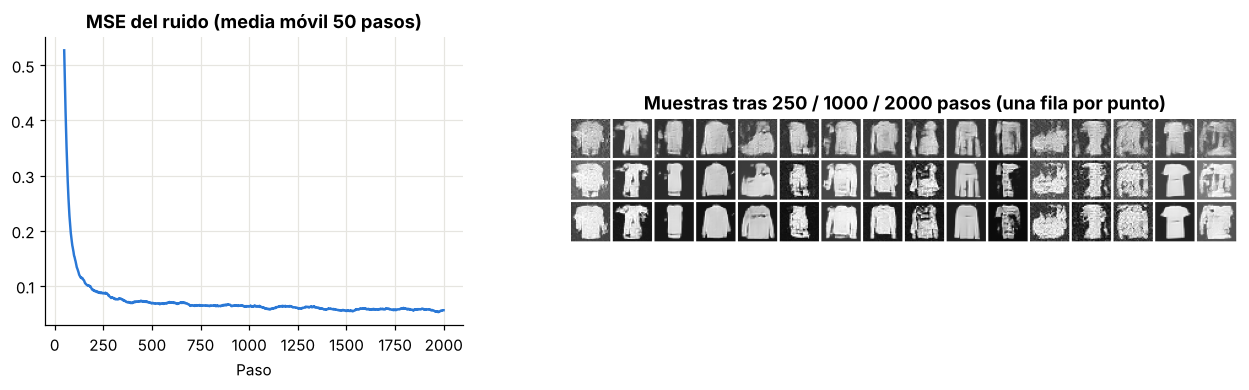

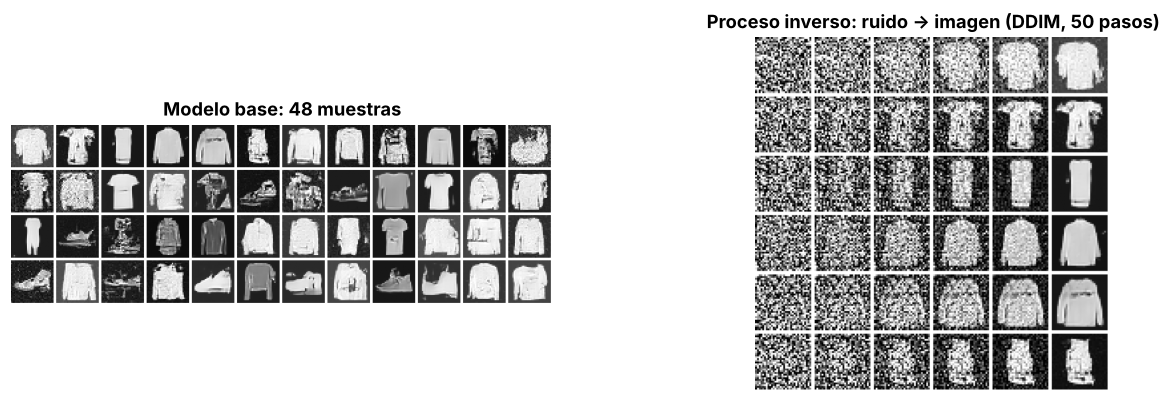

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.4), gridspec_kw={"width_ratios": [1, 1.6]})
axes[0].plot(pd.Series(hist_pre).rolling(50).mean(), color=AZUL); axes[0].set_title("MSE del ruido (media móvil 50 pasos)"); axes[0].set_xlabel("Paso")
mosaico(torch.cat(list(muestras_pre.values())), len(muestras_pre), axes[1], "Muestras tras 250 / 1000 / 2000 pasos (una fila por punto)")
guardar(fig, "02_preentrenamiento"); plt.show()
base_muestras, tray = muestrear(unet, 256)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
mosaico(base_muestras[:48], 4, axes[0], "Modelo base: 48 muestras")
mosaico(torch.stack(tray, 1).reshape(-1, 1, 32, 32), 6, axes[1], "Proceso inverso: ruido → imagen (DDIM, 50 pasos)")
guardar(fig, "02_muestras_base"); plt.show()

## 5. Clasificador independiente para medir lo generado
Una CNN pequeña entrenada con las 10 clases de Fashion-MNIST etiqueta cada imagen generada.

In [9]:
clf = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
                    nn.MaxPool2d(2), nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, 10)).to(dispositivo)
o = torch.optim.Adam(clf.parameters(), 2e-3); Xtr_t, Ytr_t = torch.tensor(X), torch.tensor(Y)
for ep in range(3):
    p = torch.randperm(len(Xtr_t))
    for i in range(0, len(p), 256):
        b = p[i:i + 256]; l = nn.functional.cross_entropy(clf(Xtr_t[b].to(dispositivo)), Ytr_t[b].to(dispositivo)); o.zero_grad(); l.backward(); o.step()
clf.eval()
with torch.no_grad(): acc_clf = (clf(torch.tensor(Xt)).argmax(1).numpy() == Yt).mean()
print(f"Exactitud del clasificador en test: {acc_clf:.3f}")
@torch.no_grad()
def distribucion(imgs):
    return np.bincount(clf(imgs.to(dispositivo)).argmax(1).cpu().numpy(), minlength=10) / len(imgs)
dist_base = distribucion(base_muestras)
print("Modelo base — % de muestras clasificadas como bolso:", round(100 * dist_base[BOLSO], 1))

Exactitud del clasificador en test: 0.807
Modelo base — % de muestras clasificadas como bolso: 16.8


## 6. Fine-tuning con LoRA (Low-Rank Adaptation)

LoRA (Hu et al., 2022) congela cada matriz de pesos $W_0$ y aprende una corrección de bajo rango: $W = W_0 + \frac{\alpha}{r}BA$,
con $B\in\mathbb R^{d\times r}$, $A\in\mathbb R^{r\times k}$ y $r\ll d$. Es la técnica estándar para ajustar Stable Diffusion con
pocas imágenes y poca memoria. Se inyectan adaptadores de rango 8 en las proyecciones de atención (`to_q`, `to_k`, `to_v`,
`to_out.0`) y en las convoluciones de los bloques residuales.

In [10]:
unet_lora = copy.deepcopy(unet)
for p in unet_lora.parameters(): p.requires_grad_(False)          # congelar el modelo base
config_lora = LoraConfig(r=8, lora_alpha=8, init_lora_weights="gaussian",
                         target_modules=["to_q", "to_k", "to_v", "to_out.0", "conv1", "conv2"])
unet_lora = inject_adapter_in_model(config_lora, unet_lora)
params_lora = [p for n, p in unet_lora.named_parameters() if "lora_" in n]
for p in params_lora: p.requires_grad_(True)
n_lora, n_total = sum(p.numel() for p in params_lora), sum(p.numel() for p in unet.parameters())
print(f"Parámetros entrenables con LoRA: {n_lora:,} ({100 * n_lora / n_total:.1f} % de {n_total:,})")

def ajustar(modelo, parametros, pasos=400, lr=1e-3, lote=32, semilla=2):
    o = torch.optim.AdamW(parametros, lr=lr); g = torch.Generator().manual_seed(semilla); h = []
    for paso in range(pasos):
        xb = X_bolso[torch.randint(0, len(X_bolso), (lote,), generator=g)]
        xb = torch.where(torch.rand(lote, 1, 1, 1, generator=g) < 0.5, xb.flip(3), xb).to(dispositivo)   # espejo
        h.append(paso_difusion(modelo, xb, o, parametros))
    return h
t0 = time.time(); hist_lora = ajustar(unet_lora, params_lora, lr=1e-3); seg_lora = time.time() - t0
print(f"Fine-tuning LoRA: {len(hist_lora)} pasos en {seg_lora:.0f} s | MSE final {np.mean(hist_lora[-50:]):.4f}")

Parámetros entrenables con LoRA: 206,592 (7.6 % de 2,734,945)


Fine-tuning LoRA: 400 pasos en 165 s | MSE final 0.0662


In [11]:
# Comparación: fine-tuning completo (todos los pesos)
unet_full = copy.deepcopy(unet)
t0 = time.time(); hist_full = ajustar(unet_full, list(unet_full.parameters()), lr=2e-4); seg_full = time.time() - t0
print(f"Fine-tuning completo: {len(hist_full)} pasos en {seg_full:.0f} s | MSE final {np.mean(hist_full[-50:]):.4f}")

Fine-tuning completo: 400 pasos en 164 s | MSE final 0.0621


## 7. Resultados del fine-tuning

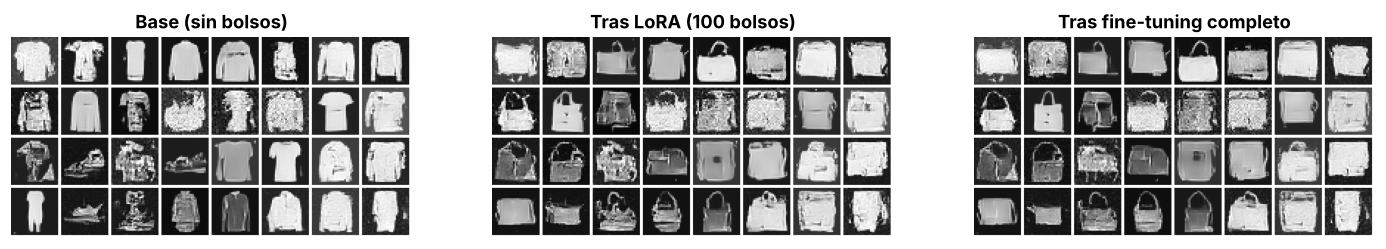

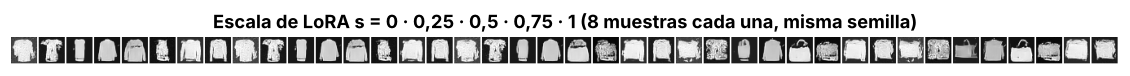

In [12]:
lora_muestras, _ = muestrear(unet_lora, 256)
full_muestras, _ = muestrear(unet_full, 256)

def escala_lora(modelo, s):
    """Escala la contribución de LoRA: W = W0 + s·(α/r)·BA  (s = 0 recupera el modelo base exacto)."""
    for m in modelo.modules():
        if hasattr(m, "scaling") and isinstance(m.scaling, dict):
            m.scaling["default"] = s * config_lora.lora_alpha / config_lora.r
escalas = {}
for s in [0.0, 0.25, 0.5, 0.75, 1.0]:
    escala_lora(unet_lora, s); escalas[s] = muestrear(unet_lora, 256)[0]
escala_lora(unet_lora, 1.0)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
mosaico(base_muestras[:32], 4, axes[0], "Base (sin bolsos)"); mosaico(lora_muestras[:32], 4, axes[1], "Tras LoRA (100 bolsos)")
mosaico(full_muestras[:32], 4, axes[2], "Tras fine-tuning completo")
guardar(fig, "02_antes_despues"); plt.show()
fig, ax = plt.subplots(figsize=(13, 2.4))
mosaico(torch.cat([escalas[s][:8] for s in escalas]), 1, ax, "Escala de LoRA s = 0 · 0,25 · 0,5 · 0,75 · 1 (8 muestras cada una, misma semilla)")
guardar(fig, "02_escala_lora"); plt.show()

,Base,LoRA,Fine-tuning completo
camiseta,3.5,0.4,0.0
pantalón,5.1,0.0,0.4
suéter,58.2,35.2,35.9
vestido,0.0,0.0,0.0
abrigo,1.2,0.0,0.0
sandalia,2.7,0.0,0.0
camisa,4.7,1.2,0.4
tenis,0.8,0.0,0.0
bolso,16.8,63.3,63.3
botín,7.0,0.0,0.0


,0.00,0.25,0.50,0.75,1.00
% bolso,16.8,26.6,41.4,53.9,63.3


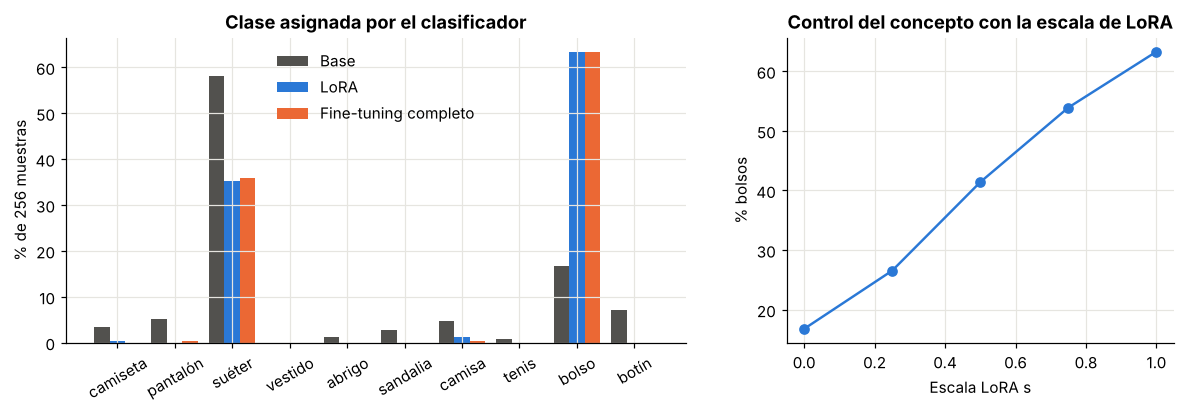

In [13]:
tabla = pd.DataFrame({"Base": distribucion(base_muestras), "LoRA": distribucion(lora_muestras),
                      "Fine-tuning completo": distribucion(full_muestras)}, index=CLASES_FASHION) * 100
tabla_esc = pd.Series({s: 100 * distribucion(im)[BOLSO] for s, im in escalas.items()}, name="% bolso")
display(tabla.round(1)); display(tabla_esc.round(1).to_frame().T)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1.6, 1]})
x = np.arange(10); w = 0.27
for k, (n, c) in enumerate(zip(tabla.columns, [GRIS, AZUL, NARANJA])):
    axes[0].bar(x + (k - 1) * w, tabla[n], w, color=c, label=n)
axes[0].set_xticks(x, CLASES_FASHION, rotation=30); axes[0].set_ylabel("% de 256 muestras"); axes[0].legend(); axes[0].set_title("Clase asignada por el clasificador")
axes[1].plot(list(tabla_esc.index), tabla_esc.values, "o-", color=AZUL); axes[1].set_xlabel("Escala LoRA s"); axes[1].set_ylabel("% bolsos")
axes[1].set_title("Control del concepto con la escala de LoRA")
guardar(fig, "02_distribucion_clases"); plt.show()

In [14]:
# Diversidad y memorización: ¿copia los 100 bolsos de entrenamiento?
def analisis(imgs):
    if len(imgs) < 2: return {"dist. media al bolso de entrenamiento más cercano": float("nan"), "diversidad (dist. media entre pares)": float("nan")}
    v = imgs.reshape(len(imgs), -1); d = torch.cdist(v, X_bolso.view(100, -1)).min(1).values
    return {"dist. media al bolso de entrenamiento más cercano": d.mean().item(), "diversidad (dist. media entre pares)": torch.pdist(v).mean().item()}
with torch.no_grad():
    bolsos_lora = lora_muestras[clf(lora_muestras).argmax(1).cpu() == BOLSO]
    bolsos_full = full_muestras[clf(full_muestras).argmax(1).cpu() == BOLSO]
mem = pd.DataFrame({"LoRA (muestras 'bolso')": analisis(bolsos_lora), "Completo (muestras 'bolso')": analisis(bolsos_full),
                    "Bolsos reales de test": analisis(torch.tensor(Xt[Yt == BOLSO][:256]))}).T
display(mem.round(2))
d_rr = torch.cdist(X_bolso.view(100, -1), X_bolso.view(100, -1)); d_rr.fill_diagonal_(float("inf"))
print(f"Referencia: distancia media entre un bolso de entrenamiento y el más cercano de los otros 99: {d_rr.min(1).values.mean():.2f}")
json.dump({"pasos_pre": PASOS_PRE, "seg_pre": seg_pre, "param_unet": n_total, "param_lora": n_lora, "pct_lora": 100 * n_lora / n_total,
           "seg_lora": seg_lora, "seg_full": seg_full, "acc_clf": float(acc_clf), "dist": tabla.round(2).to_dict(),
           "escala": tabla_esc.round(2).to_dict(), "memorizacion": mem.round(3).to_dict(orient="index"),
           "mse_pre_final": float(np.mean(hist_pre[-250:])), "mse_lora_final": float(np.mean(hist_lora[-50:])), "mse_full_final": float(np.mean(hist_full[-50:]))},
          open("resultados/nb02.json", "w"), indent=2)
torch.save({n: p for n, p in unet_lora.state_dict().items() if "lora_" in n}, "modelos/lora_bolso.pt")

,dist. media al bolso de entrenamiento más cercano,diversidad (dist. media entre pares)
LoRA (muestras 'bolso'),15.39,21.28
Completo (muestras 'bolso'),14.29,20.54
Bolsos reales de test,12.11,22.10


Referencia: distancia media entre un bolso de entrenamiento y el más cercano de los otros 99: 11.90


**Análisis.** El modelo base, que nunca vio bolsos, genera las 9 prendas del preentrenamiento. Con solo 100 imágenes y
entrenando ≈ unos pocos % de los parámetros, LoRA le enseña el concepto nuevo: la mayoría de las muestras pasan a ser bolsos, y la
escala s permite dosificar el concepto o volver exactamente al modelo base (s = 0), sin haber modificado sus pesos. El fine-tuning
completo también aprende el concepto, pero reescribe todos los pesos (el modelo base se pierde) y necesita guardar una copia
completa del modelo. Es exactamente el flujo con el que se personaliza Stable Diffusion: `UNet` + `DDPMScheduler` + LoRA con
`peft`, solo que allí la U-Net opera sobre el espacio latente de un VAE y está condicionada por texto (notebook 03).